**Data Selection**


Dataset Name and Source

For my final project I selected a spinal tumor dataset from the National Cancer Institute’s Surveillance, Epidemiology, and End Results (SEER) Research Data, 1975–2023 (November 2025 Submission). The dataset includes both adult and pediatric patients.

Source URL: https://seer.cancer.gov/data/

Reason for Selection

I chose this dataset because of my work as a neurosurgery resident and my interest in spinal tumors. I have a sincere interest in oncology research and disparities in care and outcomes, so this felt like a good opportunity to explore a topic that is relevant to my career. I also find SEER to be a thorough, well-organized database, which made it a good choice for this project.

Verification of Project Criteria

I confirmed that the dataset meets the project requirements. It includes over 5000 observations and at least 10 predictor variables, and the selected outcome is binary, making it suitable for supervised classification.




In [1]:
import pandas as pd
from google.colab import files
from io import BytesIO

def validate_dataset(data):
    """Check the SEER columns and outcome needed by this notebook."""
    required_columns = [
        "Age recode with <1 year olds and 90+",
        "Sex",
        "Year of diagnosis",
        "Primary Site - labeled",
        "Histologic Type ICD-O-3",
        "Behavior recode for analysis",
        "Grade Recode (thru 2017)",
        "ICD-O-3 Hist/behav",
        "Combined Summary Stage with Expanded Regional Codes (2004+)",
        "Reason no cancer-directed surgery",
        "Radiation recode",
        "Chemotherapy recode (yes, no/unk)",
        "Time from diagnosis to treatment in days recode",
        "Median household income inflation adj to 2024",
        "Rural-Urban Continuum Code",
        "Vital status recode (study cutoff used)",
        "Race and origin recode (NHW, NHB, NHAIAN, NHAPI, Hispanic)",
    ]

    if data.empty:
        raise ValueError("The uploaded dataset contains no records.")

    if data.columns.duplicated().any():
        raise ValueError("Column names must be unique after removing spaces.")

    missing = [
        column for column in required_columns
        if column not in data.columns
    ]
    if missing:
        raise ValueError(
            "This notebook requires a compatible SEER export. "
            f"Missing columns: {missing}"
        )

    target_col = "Vital status recode (study cutoff used)"
    outcome = data[target_col].astype("string").str.strip()

    if outcome.isna().any() or not outcome.isin(["Alive", "Dead"]).all():
        raise ValueError("Every outcome must be labeled 'Alive' or 'Dead'.")

    if outcome.nunique() != 2:
        raise ValueError("Both outcome groups are required.")

    # Ensure the stratified split has enough records per outcome
    if outcome.value_counts().min() < 5:
        raise ValueError("At least five records per outcome group are required.")

    year = pd.to_numeric(data["Year of diagnosis"], errors="coerce")
    if year.isna().any() or (year % 1 != 0).any():
        raise ValueError("Diagnosis year must contain valid whole-number years.")

    data["Year of diagnosis"] = year.astype(int)
    data[target_col] = outcome

    return data


uploaded = files.upload()

if len(uploaded) != 1:
    raise ValueError("Upload exactly one CSV file.")

filename = next(iter(uploaded))

if not filename.lower().endswith(".csv"):
    raise ValueError("Please upload a CSV file.")

try:
    df = pd.read_csv(BytesIO(uploaded[filename]))
except (pd.errors.ParserError, pd.errors.EmptyDataError, UnicodeDecodeError) as error:
    raise ValueError(
        "The CSV could not be read. Check its format and encoding."
    ) from error

df.columns = df.columns.str.strip()
df = validate_dataset(df)

print("Upload and basic validation successful.")
print("Records:", len(df))
print("Columns:", len(df.columns))
print("Records by outcome:")
display(
    df["Vital status recode (study cutoff used)"]
    .value_counts()
    .to_frame("Count")
)

# Automated structure and data-type profiling
df.info()

Saving SEER_FINAL.csv to SEER_FINAL (1).csv
Upload and basic validation successful.
Records: 5831
Columns: 25
Records by outcome:


,Count
Vital status recode (study cutoff used),
Alive,3789
Dead,2042


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5831 entries, 0 to 5830
Data columns (total 25 columns):
 #   Column                                                       Non-Null Count  Dtype 
---  ------                                                       --------------  ----- 
 0   Age recode with <1 year olds and 90+                         5831 non-null   object
 1   Sex                                                          5831 non-null   object
 2   Year of diagnosis                                            5831 non-null   int64 
 3   Primary Site - labeled                                       5831 non-null   object
 4   Histologic Type ICD-O-3                                      5831 non-null   int64 
 5   Behavior recode for analysis                                 5831 non-null   object
 6   Grade Recode (thru 2017)                                     5831 non-null   object
 7   ICD-O-3 Hist/behav                                           5831 non-null   object
 8 

In [2]:
# Record software versions for reproducibility
import sys
from importlib.metadata import version, PackageNotFoundError

packages = [
    "pandas",
    "numpy",
    "matplotlib",
    "seaborn",
    "scipy",
    "scikit-learn",
    "statsmodels",
]

print("Python:", sys.version.split()[0])

dependency_rows = []

for package in packages:
    try:
        installed_version = version(package)
    except PackageNotFoundError:
        raise ImportError(
            f"Required package '{package}' is missing. "
            f"Install it before continuing."
        )

    dependency_rows.append({
        "Package": package,
        "Version": installed_version,
    })

dependency_versions = pd.DataFrame(dependency_rows)
display(dependency_versions)

Python: 3.13.16


,Package,Version
0,pandas,2.2.3
1,numpy,2.1.3
2,matplotlib,3.10.0
3,seaborn,0.13.2
4,scipy,1.16.3
5,scikit-learn,1.6.1
6,statsmodels,0.15.0


In [3]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

target = "Vital status recode (study cutoff used)"
race = "Race and origin recode (NHW, NHB, NHAIAN, NHAPI, Hispanic)"

print("Vital status categories:")
display(df[target].value_counts(dropna=False))

print("Race and ethnicity categories:")
display(df[race].value_counts(dropna=False))

print("Descriptive statistics:")
display(df.describe(include="all").T)

Vital status categories:


,count
Vital status recode (study cutoff used),
Alive,3789
Dead,2042


Race and ethnicity categories:


,count
"Race and origin recode (NHW, NHB, NHAIAN, NHAPI, Hispanic)",
Non-Hispanic White,3733
Hispanic (All Races),1066
Non-Hispanic Black,535
Non-Hispanic Asian or Pacific Islander,411
Non-Hispanic Unknown Race,46
Non-Hispanic American Indian/Alaska Native,40


Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age recode with <1 year olds and 90+,5831,20,60-64 years,589,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,5831,2,Male,3284,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year of diagnosis,5831.0,NaN,NaN,NaN,2016.43303,4.030493,2010.0,2013.0,2016.0,2020.0,2023.0
Primary Site - labeled,5831,3,C41.2-Vertebral column,3181,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Histologic Type ICD-O-3,5831.0,NaN,NaN,NaN,9462.005831,326.251113,8000.0,9391.0,9421.0,9731.0,9930.0
Behavior recode for analysis,5831,3,Malignant,5693,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Grade Recode (thru 2017),5831,8,Blank(s),2424,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ICD-O-3 Hist/behav,5831,133,9731/3: Solitary plasmacytoma of bone,1337,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Combined Summary Stage with Expanded Regional Codes (2004+),5831,6,Localized only,4174,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RX Summ--Surg Prim Site (1998-2022),5831,18,00,2169,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Target and Predictor Variables**

My target variable is vital status at the study cutoff: alive or dead. There are 3,789 records classified as alive and 2,042 classified as dead. Patients have different lengths of follow-up, so I will need to consider that when interpreting the results.

The predictors I am considering include age group, sex, race and ethnicity, year of diagnosis, tumor location, histology, behavior, grade, stage, and treatment information, including surgery, radiation, and chemotherapy. I am also considering time to treatment, county-level median household income, and rurality. These variables are relevant to my interest in racial and ethnic differences in treatment receipt and vital status. Histology is particularly important because different spinal tumors have very different treatment approaches and prognoses.

Before building the model, I will remove columns that are entirely missing or contain the same value for every record and address overlapping variables and changes in surgery coding. I will treat histology codes as categories rather than numerical measurements. I will exclude survival duration and cause-of-death classification from the predictors because they contain information about the outcome I am trying to predict.

In [4]:
# Descriptive statistics for all variables
display(df.describe(include="all").T)

# Counts and percentages for selected categorical variables
columns = [
    "Age recode with <1 year olds and 90+",
    "Sex",
    "Race and origin recode (NHW, NHB, NHAIAN, NHAPI, Hispanic)",
    "Primary Site - labeled",
    "ICD-O-3 Hist/behav",
    "Reason no cancer-directed surgery",
    "Radiation recode",
    "Chemotherapy recode (yes, no/unk)",
    "Vital status recode (study cutoff used)"
]

for column in columns:
    print(f"\n{column}")

    counts = df[column].value_counts(dropna=False)
    summary = pd.DataFrame({
        "Count": counts,
        "Percent": (counts / len(df) * 100).round(1)
    })

    display(summary)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age recode with <1 year olds and 90+,5831,20,60-64 years,589,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,5831,2,Male,3284,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year of diagnosis,5831.0,NaN,NaN,NaN,2016.43303,4.030493,2010.0,2013.0,2016.0,2020.0,2023.0
Primary Site - labeled,5831,3,C41.2-Vertebral column,3181,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Histologic Type ICD-O-3,5831.0,NaN,NaN,NaN,9462.005831,326.251113,8000.0,9391.0,9421.0,9731.0,9930.0
Behavior recode for analysis,5831,3,Malignant,5693,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Grade Recode (thru 2017),5831,8,Blank(s),2424,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ICD-O-3 Hist/behav,5831,133,9731/3: Solitary plasmacytoma of bone,1337,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Combined Summary Stage with Expanded Regional Codes (2004+),5831,6,Localized only,4174,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RX Summ--Surg Prim Site (1998-2022),5831,18,00,2169,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Age recode with <1 year olds and 90+


,Count,Percent
Age recode with <1 year olds and 90+,,
60-64 years,589,10.1
65-69 years,569,9.8
55-59 years,527,9.0
70-74 years,494,8.5
50-54 years,445,7.6
75-79 years,374,6.4
45-49 years,368,6.3
80-84 years,324,5.6
40-44 years,313,5.4



Sex


,Count,Percent
Sex,,
Male,3284,56.3
Female,2547,43.7


...

,Count,Percent
Radiation recode,,
None/Unknown,2840,48.7
Beam radiation,2833,48.6
"Recommended, unknown if administered",91,1.6
Refused (1988+),30,0.5
"Radiation, NOS method or source not specified",23,0.4
Combination of beam with implants or isotopes,12,0.2
Radioactive implants (includes brachytherapy) (1988+),2,0.0



Chemotherapy recode (yes, no/unk)


,Count,Percent
"Chemotherapy recode (yes, no/unk)",,
No/Unknown,4255,73.0
Yes,1576,27.0



Vital status recode (study cutoff used)


,Count,Percent
Vital status recode (study cutoff used),,
Alive,3789,65.0
Dead,2042,35.0


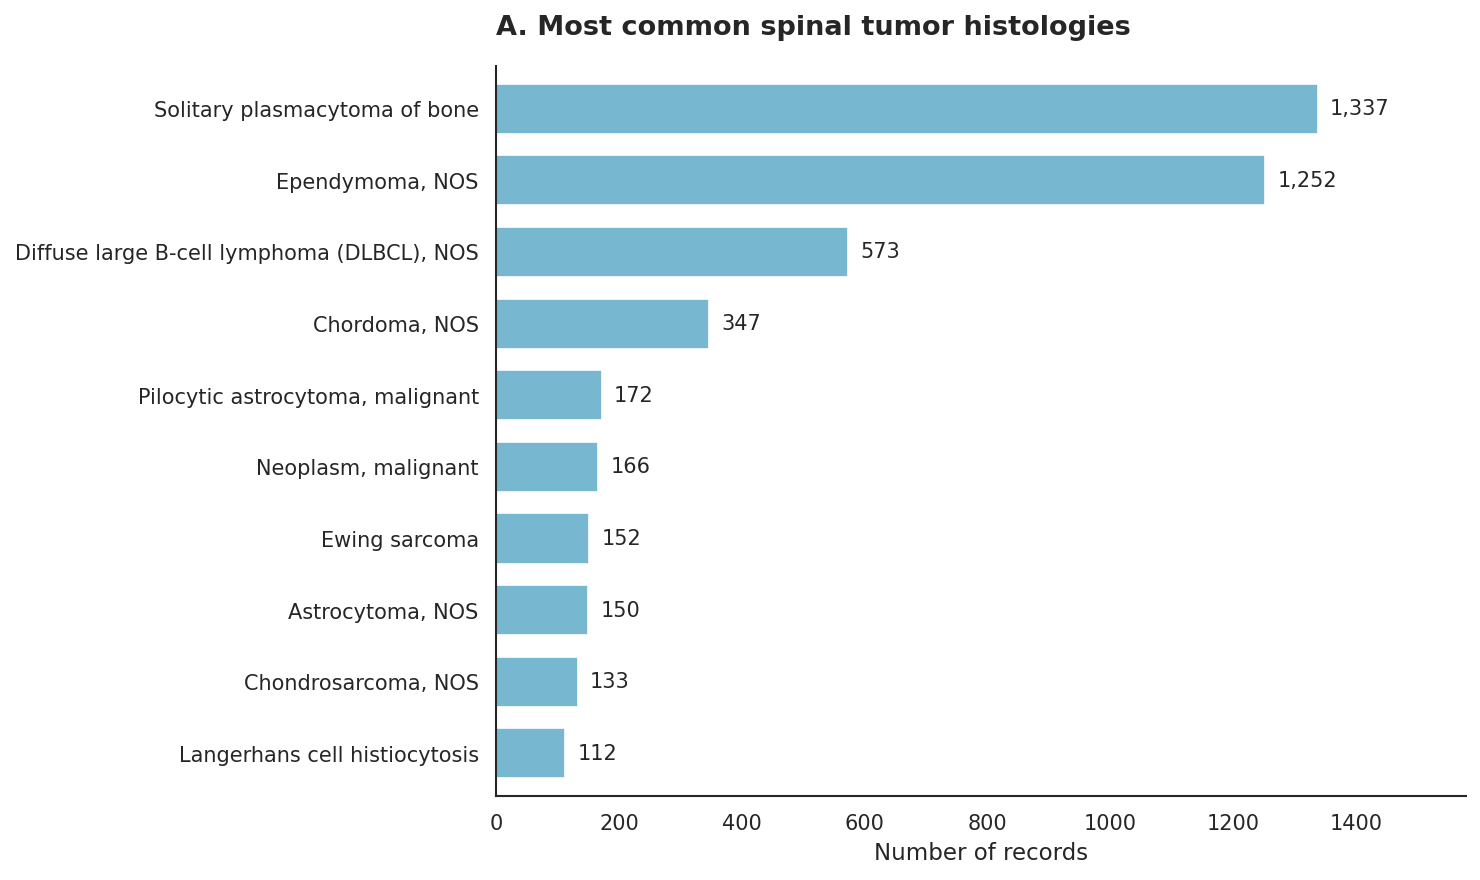

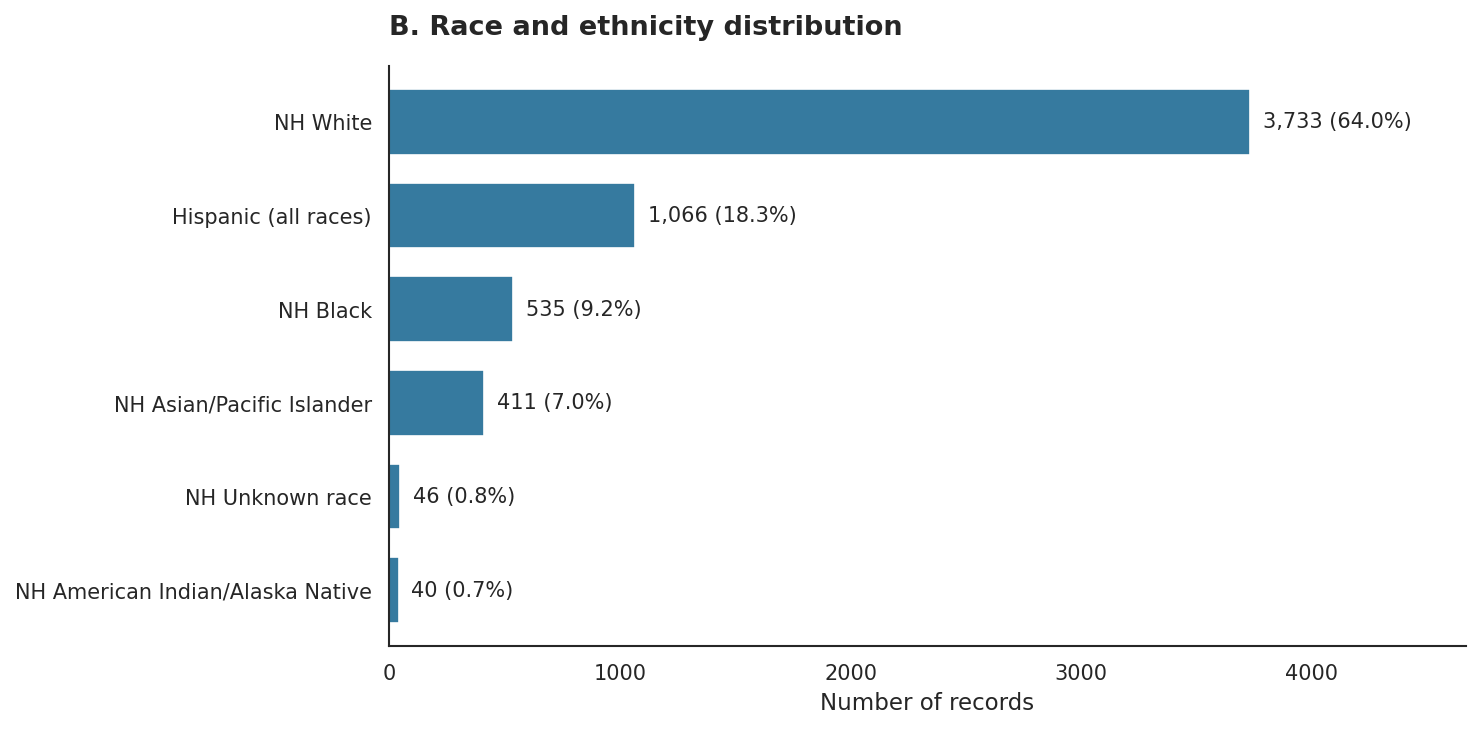

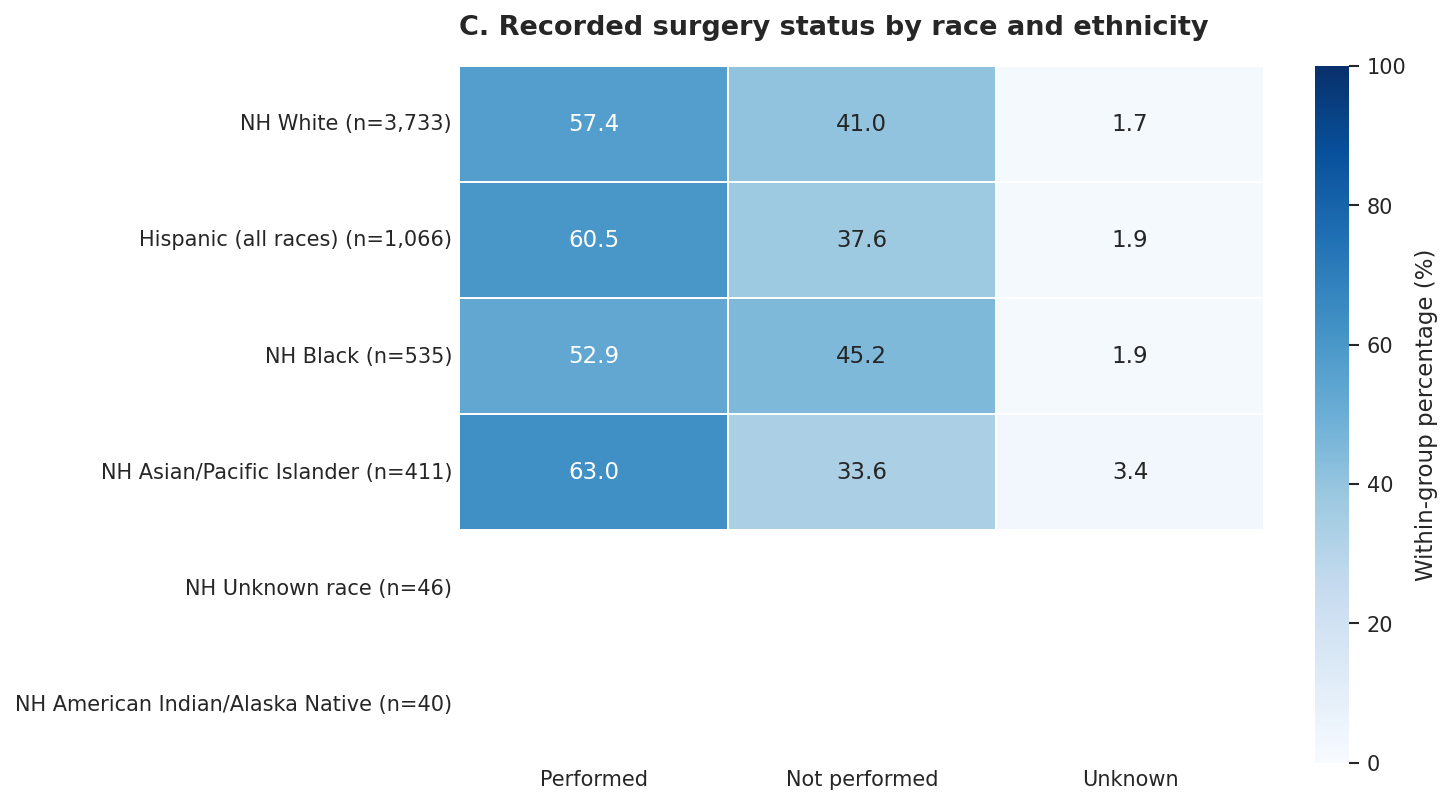

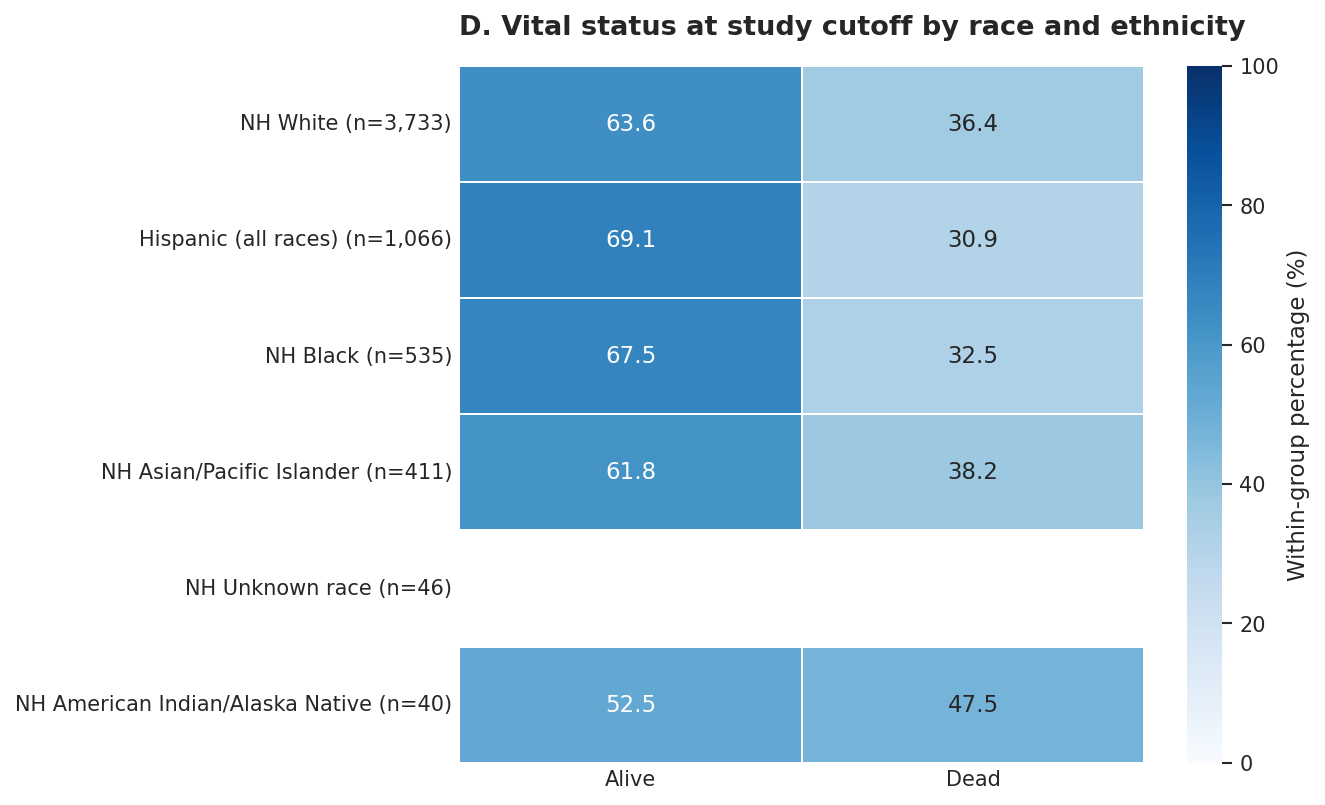

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Consistent figure formatting
sns.set_theme(style="white", context="paper", font_scale=1.2)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 150,
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

df.columns = df.columns.str.strip()

race = "Race and origin recode (NHW, NHB, NHAIAN, NHAPI, Hispanic)"
histology = "ICD-O-3 Hist/behav"
surgery = "Reason no cancer-directed surgery"
target = "Vital status recode (study cutoff used)"

# Clean labels without changing the original dataset
plot_data = df[[race, histology, surgery, target]].copy()
for column in plot_data.columns:
    plot_data[column] = plot_data[column].astype("string").str.strip()

race_labels = {
    "Non-Hispanic White": "NH White",
    "Non-Hispanic Black": "NH Black",
    "Non-Hispanic Asian or Pacific Islander": "NH Asian/Pacific Islander",
    "Non-Hispanic American Indian/Alaska Native":
        "NH American Indian/Alaska Native",
    "Hispanic (All Races)": "Hispanic (all races)",
    "Non-Hispanic Unknown Race": "NH Unknown race"
}

race_counts = plot_data[race].value_counts()
race_order = race_counts.index

def label_groups(table):
    table = table.reindex(race_order).copy()
    table.index = [
        f"{race_labels.get(group, group)} (n={race_counts[group]:,})"
        for group in table.index
    ]
    return table

def finish_figure(fig, filename):
    fig.tight_layout()
    fig.savefig(f"{filename}.png", dpi=600, bbox_inches="tight")
    fig.savefig(f"{filename}.pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)

# --------------------------------------------------
# Figure 1: Ten most common histologies
# --------------------------------------------------
hist_counts = plot_data[histology].value_counts().head(10)
hist_counts.index = hist_counts.index.str.replace(
    r"^\d+/\d+:\s*", "", regex=True
)
hist_counts = hist_counts.sort_values()

fig, ax = plt.subplots(figsize=(10, 6))
hist_counts.plot.barh(ax=ax, color="#78B7D0", width=0.7)

ax.set_title("A. Most common spinal tumor histologies", loc="left", pad=15)
ax.set_xlabel("Number of records")
ax.set_ylabel("")
ax.set_xlim(0, hist_counts.max() * 1.18)

for position, count in enumerate(hist_counts):
    ax.text(
        count + hist_counts.max() * 0.015,
        position,
        f"{count:,}",
        va="center",
        fontsize=10
    )

sns.despine(ax=ax)
finish_figure(fig, "Figure1_histology")

# --------------------------------------------------
# Figure 2: Race and ethnicity distribution
# --------------------------------------------------
race_plot = race_counts.rename(index=race_labels).sort_values()

fig, ax = plt.subplots(figsize=(10, 5))
race_plot.plot.barh(ax=ax, color="#367A9F", width=0.7)

ax.set_title("B. Race and ethnicity distribution", loc="left", pad=15)
ax.set_xlabel("Number of records")
ax.set_ylabel("")
ax.set_xlim(0, race_plot.max() * 1.25)

for position, count in enumerate(race_plot):
    percentage = count / len(plot_data) * 100
    ax.text(
        count + race_plot.max() * 0.015,
        position,
        f"{count:,} ({percentage:.1f}%)",
        va="center",
        fontsize=10
    )

sns.despine(ax=ax)
finish_figure(fig, "Figure2_race_ethnicity")

# Classify surgery receipt using explicit labels
# An unknown reason for nonreceipt is still confirmed nonreceipt
surgery_mapping = {
    "Surgery performed": "Performed",
    "Not recommended": "Not performed",
    "Recommended but not performed, unknown reason": "Not performed",
    "Recommended but not performed, patient refused": "Not performed",
    "Not recommended, contraindicated due to other cond; autopsy only (1973-2002)": "Not performed",
    "Not performed, patient died prior to recommended surgery": "Not performed",
    "Unknown; death certificate; or autopsy only (2003+)": "Unknown",
    "Recommended, unknown if performed": "Unknown",
}

s = plot_data[surgery].astype("string").str.strip()

unexpected = s.notna() & ~s.isin(surgery_mapping)
if unexpected.any():
    raise ValueError(
        f"Review unexpected surgery labels: {s[unexpected].unique().tolist()}"
    )

surgery_status = s.map(surgery_mapping).fillna("Unknown")

# --------------------------------------------------
# Figure 3: Surgery status by race and ethnicity
# --------------------------------------------------
surgery_pct = pd.crosstab(
    plot_data[race], surgery_status, normalize="index"
).mul(100)

surgery_pct = label_groups(surgery_pct).reindex(
    columns=["Performed", "Not performed", "Unknown"],
    fill_value=0
)

# Hide entire rows containing surgery counts of 1–4
surgery_counts = pd.crosstab(
    plot_data[race], surgery_status
).reindex(
    index=race_order,
    columns=["Performed", "Not performed", "Unknown"],
    fill_value=0
)

suppress_rows = (
    surgery_counts.ge(1) & surgery_counts.le(4)
).any(axis=1)

surgery_mask = pd.DataFrame(
    False,
    index=surgery_pct.index,
    columns=surgery_pct.columns
)

surgery_mask.loc[
    surgery_mask.index[suppress_rows.to_numpy()], :
] = True

fig, ax = plt.subplots(figsize=(10, 5.5))

sns.heatmap(
    surgery_pct,
    mask=surgery_mask,
    ax=ax,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    linewidths=0.8,
    linecolor="white",
    annot_kws={"fontsize": 11},
    cbar_kws={"label": "Within-group percentage (%)"}
)

ax.set_title(
    "C. Recorded surgery status by race and ethnicity",
    loc="left",
    pad=15
)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="both", length=0)
plt.setp(ax.get_yticklabels(), rotation=0)

finish_figure(fig, "Figure3_surgery_by_race")

# --------------------------------------------------
# Figure 4: Vital status by race and ethnicity
# --------------------------------------------------
vital_pct = pd.crosstab(
    plot_data[race], plot_data[target], normalize="index"
).mul(100)

vital_pct = label_groups(vital_pct).reindex(
    columns=["Alive", "Dead"], fill_value=0
)

# Mask rows containing vital-status counts of 1–4
vital_counts = pd.crosstab(
    plot_data[race], plot_data[target]
).reindex(
    index=race_order,
    columns=["Alive", "Dead"],
    fill_value=0
)

small_vital_rows = (
    vital_counts.ge(1) & vital_counts.le(4)
).any(axis=1)

vital_mask = pd.DataFrame(
    False, index=vital_pct.index, columns=vital_pct.columns
)
vital_mask.loc[
    vital_mask.index[small_vital_rows.to_numpy()], :
] = True

fig, ax = plt.subplots(figsize=(9, 5.5))

sns.heatmap(
    vital_pct,
    mask=vital_mask,
    ax=ax,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    linewidths=0.8,
    linecolor="white",
    annot_kws={"fontsize": 11},
    cbar_kws={"label": "Within-group percentage (%)"}
)

ax.set_title(
    "D. Vital status at study cutoff by race and ethnicity",
    loc="left",
    pad=15
)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="both", length=0)
plt.setp(ax.get_yticklabels(), rotation=0)

finish_figure(fig, "Figure4_vital_status_by_race")

In [6]:
# ==================================================
# DATA QUALITY ASSESSMENT
# ==================================================

# Assess missing values and explicitly coded unknown values
quality_rows = []

for column in df.columns:
    values = df[column].astype("string").str.strip()

    coded_unknown = (
        values.str.contains("unknown", case=False, na=False)
        | values.isin(["Blank(s)", "", "Unable to calculate"])
    )

    quality_rows.append({
        "Variable": column,
        "Missing values": int(df[column].isna().sum()),
        "Blank/unknown/unavailable values": int(coded_unknown.sum()),
        "Unique nonmissing values": int(
            values.replace({"Blank(s)": pd.NA, "": pd.NA}).nunique()
        )
    })

quality_summary = pd.DataFrame(quality_rows)

display(quality_summary)

print("Columns with no variation:")
display(
    quality_summary[
        quality_summary["Unique nonmissing values"] <= 1
    ]
)

,Variable,Missing values,Blank/unknown/unavailable values,Unique nonmissing values
0,Age recode with <1 year olds and 90+,0,0,20
1,Sex,0,0,2
2,Year of diagnosis,0,0,14
3,Primary Site - labeled,0,0,3
4,Histologic Type ICD-O-3,0,0,133
5,Behavior recode for analysis,0,0,3
6,Grade Recode (thru 2017),0,3958,7
7,ICD-O-3 Hist/behav,0,0,133
8,Combined Summary Stage with Expanded Regional ...,0,398,6
9,RX Summ--Surg Prim Site (1998-2022),0,410,17


Columns with no variation:


,Variable,Missing values,Blank/unknown/unavailable values,Unique nonmissing values
14,RX Summ--Reg LN Examined (1998-2002),0,5831,0
21,Race and origin (recommended by SEER),0,0,1


**Data Quality Assessment**

While there are no null values in the imported dataset, some information is recorded as “Blank(s),” “Unknown,” or “Unable to calculate.” Grade is blank or unknown in 3,958 records (67.9%), and time to treatment is unavailable in 882 records (15.1%). Race and ethnicity are unknown in 46 records (0.8%). Vital status is available for all 5,831 records.

I identified two columns that did not provide useful information. The regional lymph node variable is entirely blank, and the original race variable lists every record as “All races/ethnicities.” I will remove these columns and use the race and ethnicity variable that includes distinct groups.

The two surgery columns cover different diagnosis years, which explains their complementary pattern of blanks. I will review the coding definitions before combining them. Radiation and chemotherapy also include categories that combine no treatment with unknown treatment status. Because of this, I cannot assume that every patient in these categories did not receive treatment.

Before modeling, I will encode categorical variables, remove overlapping predictors, and determine how to handle unavailable information. I will also exclude survival duration and cause-of-death classification from the predictors because they contain information about the outcome. Differences in histology, follow-up duration, and the size of each racial and ethnic group will also be important when interpreting the results.

**Project Planning**

**Proposed Prediction Problem**

I want to examine whether there are racial and ethnic disparities in treatment receipt and survival status among adult and pediatric patients with spinal tumors. This is closely related to my work as a neurosurgery resident and my interest in oncology and disparities research. I will consider age, histology, tumor location, and stage when comparing groups, since these factors can influence both treatment decisions and outcomes.

For the machine learning component, I plan to build a binary classification model to predict survival status using demographic, tumor, and treatment characteristics. I also want to examine whether racial and ethnic differences in survival status persist after accounting for these characteristics. My goal is to identify patterns that warrant further investigation, while recognizing that these data cannot establish causation.

**Target Variable**

My target variable is survival status at the study cutoff, distinguishing patients who were living at that time from those who had died. These categories will be coded as 0 and 1, respectively. There are 3,789 patients recorded as living and 2,042 who had died. Patients have different lengths of follow-up, so this does not represent survival at a fixed interval after diagnosis.

**Model Evaluation**

I am emphasizing F1 when comparing the models because it considers both precision and recall. Precision, recall, and ROC-AUC will also be reported separately to explain each model’s performance. This evaluation priority was clarified after reviewing the initial results, so model selection is exploratory.

Separately, I examined racial and ethnic differences in treatment receipt and survival status using unadjusted comparisons. An additional logistic regression in the four most common histologies adjusted for age band, sex, histology, and diagnosis year.

# Project Progress: Preparing the Data for Modeling

Now I am using the findings from my exploratory analysis to prepare the data for modeling. I still want to focus primarily on racial and ethnic disparities, while also considering income and rural or urban residence. I will start by coding survival status and removing constant, redundant, and outcome-related variables. I will also decide what to do about missing variables.

In [7]:
# Create a working copy, preserving the original dataset
model_df = df.copy()

# Re-coding first so I have binary numerical output
# Code survival status: 0 = living, 1 = deceased
target_column = "Vital status recode (study cutoff used)"

model_df["Survival_status"] = (
    model_df[target_column]
    .astype("string")
    .str.strip()
    .map({"Alive": 0, "Dead": 1})
)

# Check that every record has a real/valid outcome
if model_df["Survival_status"].isna().any():
    raise ValueError("Some survival status values need review before continuing.")

model_df["Survival_status"] = model_df["Survival_status"].astype(int)

# Remove constant fields, redundant race fields, and outcome information
columns_to_remove = [
    "RX Summ--Reg LN Examined (1998-2002)",
    "Race and origin (recommended by SEER)",
    "Race recode (W, B, AI, API)",
    "Survival months",
    "Survival Days",
    "SEER other cause of death classification",
    target_column,
]

removed_columns = [
    column for column in columns_to_remove if column in model_df.columns
]
model_df = model_df.drop(columns=removed_columns)

# Show progress without displaying individual patient records
print("Working dataset shape:", model_df.shape)
print("\nRemoved columns:")
for column in removed_columns:
    print("-", column)

print("\nSurvival status counts: 0 = living, 1 = deceased")
display(model_df["Survival_status"].value_counts().sort_index())

print("\nRemaining columns:")
for column in model_df.columns:
    print("-", column)

Working dataset shape: (5831, 19)

Removed columns:
- RX Summ--Reg LN Examined (1998-2002)
- Race and origin (recommended by SEER)
- Race recode (W, B, AI, API)
- Survival months
- Survival Days
- SEER other cause of death classification
- Vital status recode (study cutoff used)

Survival status counts: 0 = living, 1 = deceased


,count
Survival_status,
0,3789
1,2042



Remaining columns:
- Age recode with <1 year olds and 90+
- Sex
- Year of diagnosis
- Primary Site - labeled
- Histologic Type ICD-O-3
- Behavior recode for analysis
- Grade Recode (thru 2017)
- ICD-O-3 Hist/behav
- Combined Summary Stage with Expanded Regional Codes (2004+)
- RX Summ--Surg Prim Site (1998-2022)
- RX Summ--Surg Prim Site 2023 (2023+)
- Reason no cancer-directed surgery
- Radiation recode
- Chemotherapy recode (yes, no/unk)
- Time from diagnosis to treatment in days recode
- Median household income inflation adj to 2024
- Rural-Urban Continuum Code
- Race and origin recode (NHW, NHB, NHAIAN, NHAPI, Hispanic)
- Survival_status




Here I made a separate working copy of the dataset so I can prepare it for modeling without changing the original data. I coded survival status as 0 for living and 1 for deceased and then confirmed that all 5,831 records had a valid outcome, which they did. I then removed the lymph-node variable because the entire column had only blank cells and the race field that only listed “All races/ethnicities.” I kept the combined race and ethnicity variable because I want to preserve that distinction when looking at disparities and that column had accurate information. I also removed survival days, survival months, and cause-of-death information from the predictors so the model is not using outcome information to make its predictions.
Next, my plan is to work through the coded missing values, decide how to handle the overlapping histology variables and surgery fields from different years, and prepare the categorical variables for modeling.

In [8]:
# Review surgery categories before creating a treatment-receipt variable
print("Reasons for no cancer-directed surgery:")
display(
    model_df["Reason no cancer-directed surgery"]
    .value_counts(dropna=False)
    .rename_axis("Category")
    .to_frame("Count")
)

Reasons for no cancer-directed surgery:


,Count
Category,
Surgery performed,3373
Not recommended,2259
Unknown; death certificate; or autopsy only (2003+),95
"Recommended but not performed, unknown reason",41
"Recommended but not performed, patient refused",24
"Not recommended, contraindicated due to other cond; autopsy only (1973-2002)",22
"Recommended, unknown if performed",15
"Not performed, patient died prior to recommended surgery",2


In [9]:
# First I'm creating explicit categories
surgery_mapping = {
    "Surgery performed": "Performed",
    "Not recommended": "Not performed",
    "Recommended but not performed, unknown reason": "Not performed",
    "Recommended but not performed, patient refused": "Not performed",
    "Not recommended, contraindicated due to other cond; autopsy only (1973-2002)": "Not performed",
    "Not performed, patient died prior to recommended surgery": "Not performed",
    "Unknown; death certificate; or autopsy only (2003+)": "Unknown",
    "Recommended, unknown if performed": "Unknown",
}

surgery_labels = (
    model_df["Reason no cancer-directed surgery"]
    .astype("string")
    .str.strip()
)

# Flagging any unexpected categories rather than silently assigning them
unmapped = surgery_labels[
    surgery_labels.notna() & ~surgery_labels.isin(surgery_mapping)
].unique()

if len(unmapped):
    raise ValueError(f"Review these unmapped surgery categories: {list(unmapped)}")

model_df["Surgery_receipt"] = (
    surgery_labels.map(surgery_mapping).fillna("Unknown")
)

# Select an initial set of 14 predictors
predictors = [
    "Age recode with <1 year olds and 90+",
    "Sex",
    "Year of diagnosis",
    "Primary Site - labeled",
    "Histologic Type ICD-O-3",
    "Behavior recode for analysis",
    "Combined Summary Stage with Expanded Regional Codes (2004+)",
    "Surgery_receipt",
    "Radiation recode",
    "Chemotherapy recode (yes, no/unk)",
    "Time from diagnosis to treatment in days recode",
    "Median household income inflation adj to 2024",
    "Rural-Urban Continuum Code",
    "Race and origin recode (NHW, NHB, NHAIAN, NHAPI, Hispanic)",
]

# Keep only the selected predictors and target in a separate dataset
selected_df = model_df[predictors + ["Survival_status"]].copy()

print("Selected dataset shape:", selected_df.shape)
print("Number of candidate predictors:", len(predictors))

print("\nSurgery receipt:")
display(
    selected_df["Surgery_receipt"]
    .value_counts()
    .rename_axis("Category")
    .to_frame("Count")
)

Selected dataset shape: (5831, 15)
Number of candidate predictors: 14

Surgery receipt:


,Count
Category,
Performed,3373
Not performed,2348
Unknown,110


In [10]:
# Before encoding I want to review missing values
columns_to_review = [
    "Combined Summary Stage with Expanded Regional Codes (2004+)",
    "Radiation recode",
    "Chemotherapy recode (yes, no/unk)",
    "Time from diagnosis to treatment in days recode",
    "Rural-Urban Continuum Code",
]

for column in columns_to_review:
    print(f"\n{column}")
    display(
        selected_df[column]
        .value_counts(dropna=False)
        .rename_axis("Category")
        .to_frame("Count")
    )


Combined Summary Stage with Expanded Regional Codes (2004+)


,Count
Category,
Localized only,4174
Distant site(s)/node(s) involved,821
Regional by direct extension only,434
Unknown/unstaged/unspecified/DCO,398
Regional lymph nodes involved only,3
Regional by both direct extension and lymph node involvement,1



Radiation recode


,Count
Category,
None/Unknown,2840
Beam radiation,2833
"Recommended, unknown if administered",91
Refused (1988+),30
"Radiation, NOS method or source not specified",23
Combination of beam with implants or isotopes,12
Radioactive implants (includes brachytherapy) (1988+),2



Chemotherapy recode (yes, no/unk)


,Count
Category,
No/Unknown,4255
Yes,1576



Time from diagnosis to treatment in days recode


,Count
Category,
000,1795
Unable to calculate,882
001,205
003,137
002,122
...,...
213,1
146,1
224,1



Rural-Urban Continuum Code


,Count
Category,
Counties in metropolitan areas ge 1 million pop,3544
"Counties in metropolitan areas of 250,000 to 1 million pop",1183
Counties in metropolitan areas of lt 250 thousand pop,437
Nonmetropolitan counties adjacent to a metropolitan area,401
Nonmetropolitan counties not adjacent to a metropolitan area,258
Unknown/missing/no match (Alaska or Hawaii - Entire State),8


In [11]:
# Now making a separate copy for the next preprocessing steps
prepared_df = selected_df.copy()

stage_col = "Combined Summary Stage with Expanded Regional Codes (2004+)"
rural_col = "Rural-Urban Continuum Code"
time_col = "Time from diagnosis to treatment in days recode"

# Simplify explicit unknown labels
prepared_df[stage_col] = prepared_df[stage_col].replace({
    "Unknown/unstaged/unspecified/DCO": "Unknown"
})

prepared_df[rural_col] = prepared_df[rural_col].replace({
    "Unknown/missing/no match (Alaska or Hawaii - Entire State)": "Unknown"
})

# Flag unavailable treatment time without assuming it means zero days
time_labels = prepared_df[time_col].astype("string").str.strip()
prepared_df["Treatment_time_unavailable"] = (
    time_labels.isna()
    | time_labels.isin(["Unable to calculate", "Blank(s)", ""])
).astype(int)

# Preserve the original treatment-time values pending numeric-code review
# Preserve radiation and chemotherapy categories exactly as recorded

print("Records retained:", len(prepared_df))
print(
    "Records with unavailable treatment time:",
    prepared_df["Treatment_time_unavailable"].sum()
)

print("\nStage categories:")
display(prepared_df[stage_col].value_counts().to_frame("Count"))

print("\nRural/urban categories:")
display(prepared_df[rural_col].value_counts().to_frame("Count"))

Records retained: 5831
Records with unavailable treatment time: 882

Stage categories:


,Count
Combined Summary Stage with Expanded Regional Codes (2004+),
Localized only,4174
Distant site(s)/node(s) involved,821
Regional by direct extension only,434
Unknown,398
Regional lymph nodes involved only,3
Regional by both direct extension and lymph node involvement,1



Rural/urban categories:


,Count
Rural-Urban Continuum Code,
Counties in metropolitan areas ge 1 million pop,3544
"Counties in metropolitan areas of 250,000 to 1 million pop",1183
Counties in metropolitan areas of lt 250 thousand pop,437
Nonmetropolitan counties adjacent to a metropolitan area,401
Nonmetropolitan counties not adjacent to a metropolitan area,258
Unknown,8


In [12]:
# Review treatment-time codes before converting them to numeric days
time_col = "Time from diagnosis to treatment in days recode"

time_counts = (
    prepared_df[time_col]
    .astype("string")
    .str.strip()
    .value_counts(dropna=False)
    .sort_index()
)

print(time_counts.to_string())

Time from diagnosis to treatment in days recode
000                    1795
001                     205
002                     122
003                     137
004                     103
005                      94
006                      97
007                     115
008                      82
009                      63
010                      65
011                      61
012                      48
013                      57
014                      70
015                      43
016                      41
017                      38
018                      48
019                      38
020                      42
021                      44
022                      40
023                      34
024                      38
025                      43
026                      47
027                      31
028                      46
029                      33
030                      27
031                      33
032                      32
033                      35


In [13]:
# Convert treatment timing while preserving missing and capped values
time_col = "Time from diagnosis to treatment in days recode"
time_labels = prepared_df[time_col].astype("string").str.strip()

# Validate labels before conversion
is_numeric = time_labels.str.fullmatch(r"\d+").fillna(False)
is_capped = time_labels.eq("731+ days").fillna(False)
is_unavailable = (
    time_labels.isna()
    | time_labels.isin(["Unable to calculate", "Blank(s)", ""])
)

unexpected = ~(is_numeric | is_capped | is_unavailable)
if unexpected.any():
    raise ValueError(
        f"Review unexpected treatment-time labels: "
        f"{time_labels[unexpected].unique().tolist()}"
    )

# Numeric values; unavailable entries remain NaN
prepared_df["Treatment_time_days_capped"] = pd.to_numeric(
    time_labels.where(is_numeric), errors="coerce"
).astype(float)

prepared_df.loc[is_capped, "Treatment_time_days_capped"] = 731

# Indicators preserve the meaning of special categories
prepared_df["Treatment_time_731plus"] = is_capped.astype(int)
prepared_df["Treatment_time_unavailable"] = is_unavailable.astype(int)

# Replace the original text field in this working dataset
prepared_df = prepared_df.drop(columns=[time_col])

print("Records retained:", len(prepared_df))
print("Unavailable treatment time:",
      prepared_df["Treatment_time_unavailable"].sum())
print("Treatment time of 731+ days:",
      prepared_df["Treatment_time_731plus"].sum())

display(prepared_df["Treatment_time_days_capped"].describe())

Records retained: 5831
Unavailable treatment time: 882
Treatment time of 731+ days: 3


,Treatment_time_days_capped
count,4949.000000
mean,24.056173
std,49.915418
min,0.000000
25%,0.000000
50%,6.000000
75%,29.000000
max,731.000000


In [14]:
from sklearn.model_selection import train_test_split

# Separate predictors from the outcome
X = prepared_df.drop(columns=["Survival_status"]).copy()
y = prepared_df["Survival_status"].copy()

# Histology codes represent categories, not numeric measurements
histology_col = "Histologic Type ICD-O-3"
X[histology_col] = X[histology_col].astype(str)

# Preserve approximate outcome proportions in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Validate the split
assert X_train.index.intersection(X_test.index).empty
assert len(X_train) + len(X_test) == len(X)

split_summary = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "Records": [len(X_train), len(X_test)],
    "Living (0)": [(y_train == 0).sum(), (y_test == 0).sum()],
    "Deceased (1)": [(y_train == 1).sum(), (y_test == 1).sum()],
    "Deceased (%)": [
        round(100 * y_train.mean(), 1),
        round(100 * y_test.mean(), 1)
    ]
})

display(split_summary)

,Dataset,Records,Living (0),Deceased (1),Deceased (%)
0,Training,4664,3031,1633,35.0
1,Testing,1167,758,409,35.0


In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numeric measurements
numeric_features = [
    "Year of diagnosis",
    "Treatment_time_days_capped",
]

# Binary indicators already coded as 0/1
binary_features = [
    "Treatment_time_unavailable",
    "Treatment_time_731plus",
]

# All remaining predictors are categorical
categorical_features = [
    column for column in X_train.columns
    if column not in numeric_features + binary_features
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
    ("binary", "passthrough", binary_features),
])

print("Preprocessing defined; not fitted yet.")
print("Numeric predictors:", len(numeric_features))
print("Categorical predictors:", len(categorical_features))
print("Binary indicators:", len(binary_features))

Preprocessing defined; not fitted yet.
Numeric predictors: 2
Categorical predictors: 12
Binary indicators: 2


# Supervised Machine Learning Models

For my machine learning models I will compare logistic regression, decision tree, and random forest models to classify survival status at the study cutoff. Each model uses the same training and test split. Preprocessing is fitted within each pipeline using only the training data. Because the predictors include treatment information, this is an exploratory classification analysis rather than a prediction made at diagnosis.

In [16]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Initial models; settings chosen without examining test performance
model_specs = {
    "Logistic regression": LogisticRegression(
        max_iter=3000,
        random_state=42
    ),
    "Decision tree": DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=20,
        random_state=42
    ),
    "Random forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ),
}

# Give each model its own preprocessing pipeline
fitted_models = {}

for name, estimator in model_specs.items():
    pipeline = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("model", estimator),
    ])

    pipeline.fit(X_train, y_train)
    fitted_models[name] = pipeline

    print(f"{name}: training completed")

Logistic regression: training completed
Decision tree: training completed
Random forest: training completed


## Model Evaluation: F1 Score

I am emphasizing F1 when comparing the models because it considers both precision and recall. Precision describes how often a classification of deceased status is correct, while recall describes how many patients recorded as deceased the model identifies. Precision, recall, and ROC-AUC are also reported separately to provide a fuller picture of model performance.

$$
F_1 = 2 \times \frac{\mathrm{Precision} \times \mathrm{Recall}}
{\mathrm{Precision} + \mathrm{Recall}}
$$

This formula combines precision and recall into a single score, rewarding models that perform well on both measures.

In [17]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)

def evaluate_model(name, pipeline, X_eval, y_eval):
    predictions = pipeline.predict(X_eval)
    probabilities = pipeline.predict_proba(X_eval)[:, 1]

    return {
        "Model": name,
        "Precision": precision_score(
            y_eval, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_eval, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_eval, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_eval, probabilities),
    }

model_comparison = pd.DataFrame([
    evaluate_model(name, pipeline, X_test, y_test)
    for name, pipeline in fitted_models.items()
]).set_index("Model")

display(model_comparison.round(3))

,Precision,Recall,F1,ROC-AUC
Model,,,,
Logistic regression,0.753,0.619,0.679,0.856
Decision tree,0.805,0.252,0.384,0.718
Random forest,0.742,0.465,0.571,0.829


In [18]:
# Select the strongest observed model using F1
primary_metric = "F1"

if primary_metric not in model_comparison.columns:
    raise ValueError(f"Evaluation metric not found: {primary_metric}")

scores = model_comparison[primary_metric]

if scores.isna().any():
    raise ValueError("Review missing model scores before selecting a model.")

best_score = scores.max()
best_models = scores.index[scores.eq(best_score)].tolist()

print("Primary comparison metric:", primary_metric)
print("Highest-scoring model(s):", ", ".join(best_models))
print(f"Highest F1 score: {best_score:.3f}")
print(
    "This is an exploratory comparison on the current test set; "
    "it does not establish that the selected model will perform best "
    "in other datasets."
)

Primary comparison metric: F1
Highest-scoring model(s): Logistic regression
Highest F1 score: 0.679
This is an exploratory comparison on the current test set; it does not establish that the selected model will perform best in other datasets.


# Inferential Analysis: Race/Ethnicity and Survival Status

For inferential stats I will examine whether survival status at the study cutoff differs across racial and ethnic groups using a chi-square test. This initial comparison is unadjusted and does not establish causation or account for differences in patient characteristics or follow-up time. Of the patient characteristics the biggest confounder is probably histology.

In [19]:
from scipy.stats import chi2_contingency

race_col = "Race and origin recode (NHW, NHB, NHAIAN, NHAPI, Hispanic)"

# Exclude unknown race from this specific comparison only
race_labels = model_df[race_col].astype("string").str.strip()
known_race = race_labels.notna() & ~race_labels.isin([
    "Non-Hispanic Unknown Race", "Unknown", "Blank(s)", ""
])

analysis_df = model_df.loc[
    known_race, [race_col, "Survival_status"]
].copy()

# Counts by race/ethnicity and survival status
race_table = pd.crosstab(
    analysis_df[race_col],
    analysis_df["Survival_status"]
).reindex(columns=[0, 1], fill_value=0)

# Check whether the contingency table supports a chi-square test
if race_table.shape[0] < 2 or (race_table.sum(axis=0) == 0).any():
    raise ValueError(
        "This comparison requires at least two racial/ethnic groups "
        "and both survival outcomes."
    )

chi2, p_value, dof, expected = chi2_contingency(race_table)

# Adapt inference when expected counts are small
if (expected < 5).any():
    from scipy.stats import random_table
    import numpy as np

    # Monte Carlo test using tables with the same row and column totals
    rng = np.random.default_rng(42)
    simulations = 10000
    simulated_tables = random_table.rvs(
        race_table.sum(axis=1).to_numpy(),
        race_table.sum(axis=0).to_numpy(),
        size=simulations,
        random_state=rng,
    )

    simulated_statistics = (
        ((simulated_tables - expected) ** 2 / expected)
        .sum(axis=(1, 2))
    )

    p_value = (
        1 + np.count_nonzero(simulated_statistics >= chi2)
    ) / (simulations + 1)

    print("Inference method: Monte Carlo chi-square test (10,000 simulations)")
else:
    print("Inference method: asymptotic chi-square test")

# Display counts and within-group percentages
summary = race_table.rename(columns={0: "Living", 1: "Deceased"})
summary["Total"] = summary["Living"] + summary["Deceased"]
summary["Deceased (%)"] = (
    100 * summary["Deceased"] / summary["Total"]
).round(1)

display(summary)

print("Records included:", len(analysis_df))
print("Records excluded for unknown race:", len(model_df) - len(analysis_df))
print(f"Chi-square statistic: {chi2:.3f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.4g}")
print(f"Smallest expected cell count: {expected.min():.2f}")

if (expected < 5).any():
    print("Some expected counts are below 5; review the test assumptions.")

Inference method: asymptotic chi-square test


Survival_status,Living,Deceased,Total,Deceased (%)
"Race and origin recode (NHW, NHB, NHAIAN, NHAPI, Hispanic)",,,,
Hispanic (All Races),737,329,1066,30.9
Non-Hispanic American Indian/Alaska Native,21,19,40,47.5
Non-Hispanic Asian or Pacific Islander,254,157,411,38.2
Non-Hispanic Black,361,174,535,32.5
Non-Hispanic White,2374,1359,3733,36.4


Records included: 5785
Records excluded for unknown race: 46
Chi-square statistic: 17.113
Degrees of freedom: 4
P-value: 0.001838
Smallest expected cell count: 14.09


My initial inferential analysis found that survival status at the study cutoff differed across racial and ethnic groups (p = 0.00184). I included 5,785 records and excluded 46 with unknown race from this comparison only. This finding supports looking more closely at the differences, but it does not tell me which specific groups differ statistically or whether the association persists after accounting for the obvious potential confounders such as age, histology, stage, and follow-up differences.

# Inferential Analysis: Race/Ethnicity and Surgery Receipt

Next, here I am comparing surgery receipt across racial and ethnic groups using a chi-square test. This is an unadjusted comparison of treatment receipt, rather than a direct measure of access. Differences may also reflect tumor characteristics, surgical recommendations, contraindications, or patient preferences. It is a rather crude way where of making initial explorations into surrogates for access.

In [20]:
# Include known race/ethnicity; retain unknown surgery receipt in the summary
surgery_analysis = model_df.loc[
    known_race, [race_col, "Surgery_receipt"]
].copy()

surgery_table = pd.crosstab(
    surgery_analysis[race_col],
    surgery_analysis["Surgery_receipt"]
).reindex(
    columns=["Performed", "Not performed", "Unknown"],
    fill_value=0
)

surgery_summary = surgery_table.copy()
surgery_summary["Total"] = surgery_table.sum(axis=1)

known_receipt_total = (
    surgery_table["Performed"] + surgery_table["Not performed"]
)

surgery_summary["Performed (% of known receipt)"] = (
    100 * surgery_table["Performed"]
    / known_receipt_total.replace(0, float("nan"))
).round(1)

# Suppress the full displayed row when any surgery count is 1–4.
# Suppressing the whole row prevents recovery from its totals or percentages.
display_summary = surgery_summary.astype(object).copy()

small_cell_rows = (
    surgery_table.ge(1) & surgery_table.le(4)
).any(axis=1)

display_summary.loc[small_cell_rows, :] = "Suppressed"

display(display_summary)
print(
    "Rows containing surgery counts of 1–4 are suppressed "
    "in this display. Statistical tests use the original counts."
)

# Test only records with known surgery receipt
test_table = surgery_table[["Performed", "Not performed"]]
test_table = test_table.loc[test_table.sum(axis=1) > 0]

chi2_surgery, p_surgery, dof_surgery, expected_surgery = (
    chi2_contingency(test_table)
)

print("Records included in test:", int(test_table.to_numpy().sum()))
print(f"Chi-square statistic: {chi2_surgery:.3f}")
print(f"Degrees of freedom: {dof_surgery}")
print(f"P-value: {p_surgery:.4g}")
print(f"Smallest expected cell count: {expected_surgery.min():.2f}")

if (expected_surgery < 5).any():
    print("Some expected counts are below 5; review the test assumptions.")

Surgery_receipt,Performed,Not performed,Unknown,Total,Performed (% of known receipt)
"Race and origin recode (NHW, NHB, NHAIAN, NHAPI, Hispanic)",,,,,
Hispanic (All Races),645,401,20,1066,61.7
Non-Hispanic American Indian/Alaska Native,Suppressed,Suppressed,Suppressed,Suppressed,Suppressed
Non-Hispanic Asian or Pacific Islander,259,138,14,411,65.2
Non-Hispanic Black,283,242,10,535,53.9
Non-Hispanic White,2141,1529,63,3733,58.3


Rows containing surgery counts of 1–4 are suppressed in this display. Statistical tests use the original counts.
Records included in test: 5677
Chi-square statistic: 15.865
Degrees of freedom: 4
P-value: 0.003206
Smallest expected cell count: 15.99


For surgery receipt I also found an overall association between race/ethnicity and surgery receipt (p = 0.00321). The test included 5,677 records with known race/ethnicity and surgery receipt. I kept unknown surgery receipt visible in the descriptive table but excluded those records from the test. These differences warrant further investigation, but they do not establish unequal access to surgery. Tumor type, stage, surgical recommendations, contraindications, and patient preferences may also contribute to the patterns.

# Model Evaluation Visualizations

Next I am using confusion matrices to examine classification errors and precision–recall curves to compare performance across different thresholds. I coded Deceased status as the positive class (1).

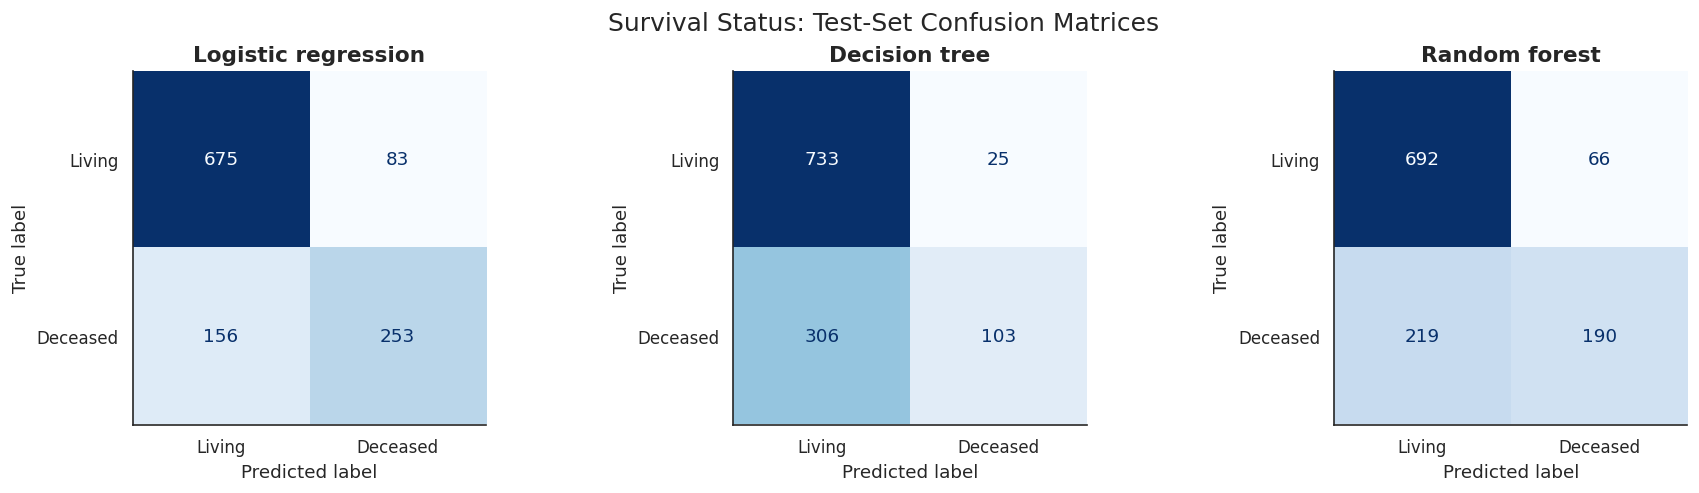

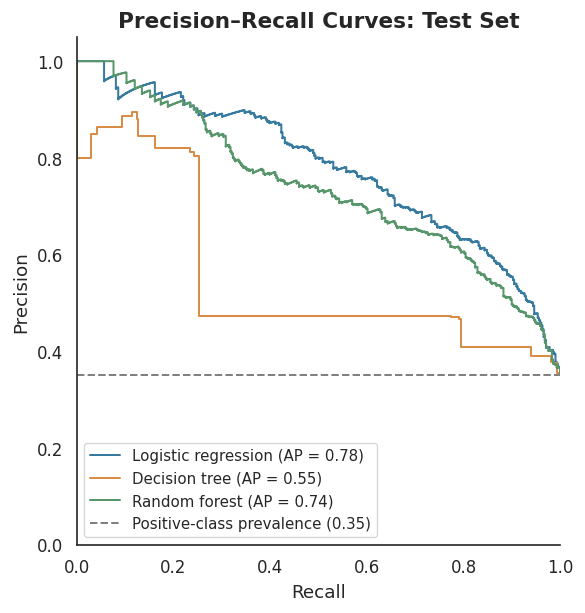

In [21]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
)

# Consistent figure styling
plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "figure.dpi": 120,
})

# Confusion matrices at each model's default threshold
fig, axes = plt.subplots(
    1, len(fitted_models),
    figsize=(15, 4),
    constrained_layout=True
)

for ax, (name, pipeline) in zip(axes, fitted_models.items()):
    predictions = pipeline.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=[0, 1],
        display_labels=["Living", "Deceased"],
        cmap="Blues",
        colorbar=False,
        values_format="d",
        ax=ax,
    )
    ax.set_title(name)

fig.suptitle("Survival Status: Test-Set Confusion Matrices", fontsize=15)
plt.show()

# Precision–recall curves across classification thresholds
fig, ax = plt.subplots(figsize=(7, 5), constrained_layout=True)
colors = ["#367A9F", "#D98C45", "#57966B"]

for (name, pipeline), color in zip(fitted_models.items(), colors):
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    PrecisionRecallDisplay.from_predictions(
        y_test,
        probabilities,
        name=name,
        color=color,
        ax=ax,
    )

# Reference: proportion of positive outcomes in the test set
ax.axhline(
    y_test.mean(),
    color="gray",
    linestyle="--",
    label=f"Positive-class prevalence ({y_test.mean():.2f})",
)

ax.set_title("Precision–Recall Curves: Test Set")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.legend(loc="lower left", fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

# Summarizing the Analysis Pipeline Enhancements

1. Additional validation and error handling: I added checks for unexpected survival-status, surgery, and treatment-time labels. These checks stop the analysis when a value needs review rather than silently assigning it to the wrong category.

2. Treatment-time feature engineering: I created indicators for unavailable treatment timing and the “731+ days” category. This preserves information that would otherwise be lost when converting treatment time to a numeric variable.

3. Reusable model evaluation: I made one evaluation function that calculates the same metrics for all three models. This reduces repeated code and makes the comparisons consistent. I'm hoping this makes the code less clunky.

4. Automated model-comparison table: I combined the evaluation results into one table containing precision, recall, F1, and ROC-AUC. This makes it easier to compare performance without manually collecting results from separate outputs. Also I just think visually it allows for quick comparison.

5. Additional evaluation visualizations: I added confusion matrices and precision–recall curves. These show the types of errors each model makes and how precision and recall change across classification thresholds.

In [22]:
# Review histology group sizes before specifying the adjusted model
histology_counts = (
    model_df["ICD-O-3 Hist/behav"]
    .value_counts()
)

print("Number of histology categories:", len(histology_counts))
print("Categories with fewer than 20 records:",
      (histology_counts < 20).sum())

# Display only the 15 most common categories
display(
    histology_counts.head(15)
    .rename_axis("Histology")
    .to_frame("Records")
)

Number of histology categories: 133
Categories with fewer than 20 records: 100


,Records
Histology,
9731/3: Solitary plasmacytoma of bone,1337
"9391/3: Ependymoma, NOS",1252
"9680/3: Diffuse large B-cell lymphoma (DLBCL), NOS",573
"9370/3: Chordoma, NOS",347
"9421/3: Pilocytic astrocytoma, malignant",172
"8000/3: Neoplasm, malignant",166
9260/3: Ewing sarcoma,152
"9400/3: Astrocytoma, NOS",150
"9220/3: Chondrosarcoma, NOS",133


In [23]:
# Check outcome counts in the four most common histologies
common_histologies = histology_counts.head(4).index

adjusted_subset = model_df.loc[
    model_df["ICD-O-3 Hist/behav"].isin(common_histologies)
].copy()

histology_outcomes = pd.crosstab(
    adjusted_subset["ICD-O-3 Hist/behav"],
    adjusted_subset["Survival_status"]
).reindex(columns=[0, 1], fill_value=0)

histology_outcomes.columns = ["Living", "Deceased"]

display(histology_outcomes)
print("Records in the additional analysis:", len(adjusted_subset))

,Living,Deceased
ICD-O-3 Hist/behav,,
"9370/3: Chordoma, NOS",226,121
"9391/3: Ependymoma, NOS",1119,133
"9680/3: Diffuse large B-cell lymphoma (DLBCL), NOS",320,253
9731/3: Solitary plasmacytoma of bone,805,532


Records in the additional analysis: 3509


## Adjusted Analysis in the Four Most Common Histologies

Here, I will use multivariable logistic regression to examine the association between race/ethnicity and survival status while adjusting for age group, sex, histology, and diagnosis year. This additional analysis is restricted to the four most common histologies to limit sparse categories without combining unrelated rare tumors.

Non-Hispanic White patients will serve as the race/ethnicity reference group. Results will be reported as adjusted odds ratios with 95% confidence intervals. These estimates describe the odds of recorded deceased status at the study cutoff, not a mortality rate or a causal effect. Differences in stage, treatment, and follow-up remain important limitations.

In [24]:
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Use short names for the additional inferential analysis
adjusted_data = adjusted_subset.rename(columns={
    "Race and origin recode (NHW, NHB, NHAIAN, NHAPI, Hispanic)": "race_ethnicity",
    "Age recode with <1 year olds and 90+": "age_group",
    "Sex": "sex",
    "ICD-O-3 Hist/behav": "histology",
    "Year of diagnosis": "diagnosis_year",
}).copy()

# Exclude unknown race from this analysis only
race_values = adjusted_data["race_ethnicity"].astype("string").str.strip()
known = race_values.notna() & ~race_values.isin([
    "Non-Hispanic Unknown Race", "Unknown", "Blank(s)", ""
])
adjusted_data = adjusted_data.loc[known].copy()

categorical_columns = ["race_ethnicity", "age_group", "sex", "histology"]

for column in categorical_columns:
    adjusted_data[column] = (
        adjusted_data[column].astype("string").str.strip()
    )

required = categorical_columns + ["diagnosis_year", "Survival_status"]
if adjusted_data[required].isna().any().any():
    raise ValueError("Review missing values in the adjusted-analysis variables.")

# Convert string columns to ordinary Python strings for formula compatibility
for column in categorical_columns:
    adjusted_data[column] = adjusted_data[column].astype(str)

    # Use broader age bands because the youngest categories are sparse
age_lower_bound = pd.to_numeric(
    adjusted_data["age_group"].str.extract(r"^(\d+)")[0],
    errors="raise"
)

adjusted_data["age_band"] = pd.cut(
    age_lower_bound,
    bins=[0, 20, 40, 60, 80, np.inf],
    labels=["0–19", "20–39", "40–59", "60–79", "80+"],
    right=False
)

if adjusted_data["age_band"].isna().any():
    raise ValueError("Some age labels could not be assigned to an age band.")

# Center year to make the intercept easier to estimate
adjusted_data["year_centered"] = (
    adjusted_data["diagnosis_year"] - 2016
)

formula = (
    'Survival_status ~ '
    'C(race_ethnicity, Treatment(reference="Non-Hispanic White"))'
    ' + C(age_band) + C(sex) + C(histology) + year_centered'
)

# This statistical model is separate from the predictive train/test comparison
adjusted_model = smf.glm(
    formula=formula,
    data=adjusted_data,
    family=sm.families.Binomial(),
    missing="raise",
)

# Check whether model coefficients can be uniquely estimated
design = adjusted_model.exog
if np.linalg.matrix_rank(design) < design.shape[1]:
    raise ValueError("The adjusted model has redundant terms; review its design.")

adjusted_result = adjusted_model.fit(maxiter=200)

if not adjusted_result.converged:
    raise RuntimeError("The adjusted regression did not converge.")

# Guard against unstable estimates from sparse or separated categories
if (
    not np.isfinite(adjusted_result.params).all()
    or not np.isfinite(adjusted_result.bse).all()
    or (adjusted_result.bse > 10).any()
):
    raise RuntimeError(
        "Potentially unstable estimates detected. "
        "Review sparse categories before interpreting this model."
    )

# Display race/ethnicity estimates only
race_terms = [
    term for term in adjusted_result.params.index
    if term.startswith("C(race_ethnicity")
]

confidence_intervals = adjusted_result.conf_int()

adjusted_race_results = pd.DataFrame({
    "Adjusted OR": np.exp(adjusted_result.params.loc[race_terms]),
    "95% CI lower": np.exp(confidence_intervals.loc[race_terms, 0]),
    "95% CI upper": np.exp(confidence_intervals.loc[race_terms, 1]),
    "P-value": adjusted_result.pvalues.loc[race_terms],
})

adjusted_race_results.index = [
    term.split("[T.", 1)[1].removesuffix("]")
    for term in race_terms
]
adjusted_race_results.index.name = "Race/ethnicity"

print("Records included:", len(adjusted_data))
print("Reference group: Non-Hispanic White")
display(adjusted_race_results.round(4))

Records included: 3487
Reference group: Non-Hispanic White


,Adjusted OR,95% CI lower,95% CI upper,P-value
Race/ethnicity,,,,
Hispanic (All Races),1.0960,0.8534,1.4077,0.4726
Non-Hispanic American Indian/Alaska Native,1.6308,0.5666,4.6938,0.3646
Non-Hispanic Asian or Pacific Islander,0.9861,0.6592,1.4751,0.9455
Non-Hispanic Black,1.2635,0.9227,1.7303,0.1448


The adjusted analysis included 3,487 records from the four most common histologies, excluding records with unknown race/ethnicity. After adjustment for age band, sex, histology, and diagnosis year, none of the racial and ethnic groups had statistically significant differences in the odds of deceased status compared with non-Hispanic White patients.

This does not necessarily establish that disparities are absent. The confidence intervals allow for potentially meaningful differences, particularly for the smaller groups. These results also cannot be directly compared with the full-cohort chi-square findings because the adjusted analysis uses a restricted subset.

The initial model produced unstable estimates because several young age categories had no deceased records. Therefore I used broader age bands while retaining all eligible records. This improved the estimation but provides less detailed age adjustment. Stage, treatment, socioeconomic factors, and unequal follow-up remain limitations of this analysis.

# Summary and Interpretation

My main interest in this project is whether treatment receipt and survival status differ across racial and ethnic groups among patients with spinal tumors. The full-cohort analyses found overall associations between race/ethnicity and both survival status (p = 0.00184) and surgery receipt (p = 0.00321). These comparisons are unadjusted and do not establish unequal access to care or identify which specific groups differ statistically.

I also performed an adjusted logistic regression in 3,487 records from the four most common histologies. After accounting for age band, sex, histology, and diagnosis year, none of the racial/ethnic comparisons with non-Hispanic White patients reached statistical significance. This does not mean disparities are absent, particularly given the uncertainty in estimates for smaller groups. Because this analysis used a restricted subset, it cannot establish why the full-cohort and adjusted findings differ.

To provide some clinical background on these four pathologies, first Chordomas. Chordomas, are rather devestating bone tumors that carry a somewhat dim prognosis because of their likelihood to recur. They typically require what is called a sacrectomy which is where you must remove an entire sacrum, typically lasting anywhere from 10-14 hours.

Ependymomas are the most common intramedullary spinal cord tumor (i.e in the spinal cord as opposed to the bones of the spine). This requires opening of the spinal cord and careful removal of the tumor in an en bloc fashion. These can be anywhere from grade 1-3 with low grade tumors carrying a quite good prognosis.

Solitary plasmacytoma of the bone and diffuse large B-Cell lymphomas are more rare tumors and typically can be treated non-surgically except for in the case of significant cord compression. Regardless, metastasis of any tumors to the spine usually indicate significant progression of disease and must be treated urgently.

For the classification models, logistic regression had the highest F1 score (0.679) and ROC-AUC (0.856) on the held-out test set. Its precision was 0.753 and recall was 0.619. The decision tree had higher precision but substantially lower recall, while the random forest fell between the two on F1. These results favor logistic regression for this exploratory comparison, but further validation is needed.

Important limitations include unequal follow-up, small racial/ethnic groups, ambiguous treatment categories, and differences in patient and tumor characteristics. The adjusted analysis did not account for stage, treatment, or socioeconomic factors, and broader age bands provided less detailed age adjustment. Survival status at the study cutoff also does not represent survival over a fixed period.

Overall, the project provides a reproducible analytical structure for exploring these questions, but the findings remain exploratory. Future work should include more comprehensive adjustment, time-to-event analysis, and additional model validation. The models use treatment information and should not be interpreted as predictions made at diagnosis or as tools ready for clinical use.